# 🚀 Complete AsyncIO Guide: Async/Await in Python

## 📚 Master Asynchronous Programming with Visual Diagrams

Welcome to the complete guide on **AsyncIO** - Python's built-in solution for writing efficient asynchronous code!

### 🎯 What You'll Learn:

1. ⚡ **What is AsyncIO?** - Understanding asynchronous programming
2. 🔄 **Event Loop** - The heart of async operations
3. 📝 **Async/Await Syntax** - Writing asynchronous code
4. 🆚 **AsyncIO vs Threading vs Multiprocessing** - When to use what
5. 🎨 **Visual Diagrams** - See how async code executes
6. 💻 **Real-World Examples** - Practical async applications
7. 📊 **Performance Comparisons** - Proof of async benefits
8. ✅ **Best Practices** - Writing efficient async code

### 💡 Why Learn AsyncIO?

AsyncIO is **perfect** for I/O-bound tasks:
- ✅ Handle **thousands** of concurrent connections
- ✅ **No GIL limitations** (single-threaded but efficient)
- ✅ **Lower overhead** than threads
- ✅ **Cleaner code** with async/await syntax
- ✅ **Better performance** for network/database operations

Let's dive in! 🏊‍♂️

In [3]:
# Import required libraries
import asyncio
import aiohttp
import time
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, Rectangle, FancyArrowPatch, Circle, Wedge
import numpy as np
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor
import requests

# Set up matplotlib for better visuals
plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

print("✅ All libraries imported successfully!")
print(f"📦 AsyncIO version: Built-in with Python {__import__('sys').version}")
print(f"🌐 aiohttp installed: {'Yes' if aiohttp else 'Yes'}")
print("\n🎯 Ready to explore AsyncIO!")

✅ All libraries imported successfully!
📦 AsyncIO version: Built-in with Python 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
🌐 aiohttp installed: Yes

🎯 Ready to explore AsyncIO!


## 1️⃣ What is Asynchronous Programming?

### 🤔 The Problem with Synchronous Code

Imagine you're making breakfast:

**❌ SYNCHRONOUS WAY (Blocking):**
```
1. Put bread in toaster → WAIT 2 minutes (doing nothing!)
2. Boil water → WAIT 3 minutes (standing idle!)
3. Make coffee → WAIT 1 minute (still waiting!)
Total: 6 minutes
```

**✅ ASYNCHRONOUS WAY (Non-blocking):**
```
1. Put bread in toaster (start) → Don't wait, move on!
2. Boil water (start) → Don't wait, move on!
3. Make coffee (start) → Don't wait!
4. While things cook, check each one when ready
Total: 3 minutes (everything done in parallel!)
```

### 💡 Key Concepts:

- **Synchronous (Blocking)**: Do one thing at a time, wait for each to complete
- **Asynchronous (Non-blocking)**: Start multiple tasks, switch between them when waiting
- **Concurrency**: Managing multiple tasks (not necessarily parallel)
- **Parallelism**: Actually running multiple tasks at the same time (requires multiple CPU cores)

AsyncIO gives us **concurrency** without **parallelism** - perfect for I/O-bound tasks!

C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\3565524061.py:91: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\3565524061.py:91: UserWarning: Glyph 9208 (\N{DOUBLE VERTICAL BAR}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\3565524061.py:91: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\3565524061.py:91: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\3565524061.py:91: UserWarning: Glyph 9201 (\N{STOPWATCH}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\3565524061.py:91: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) Arial.
  plt.ti

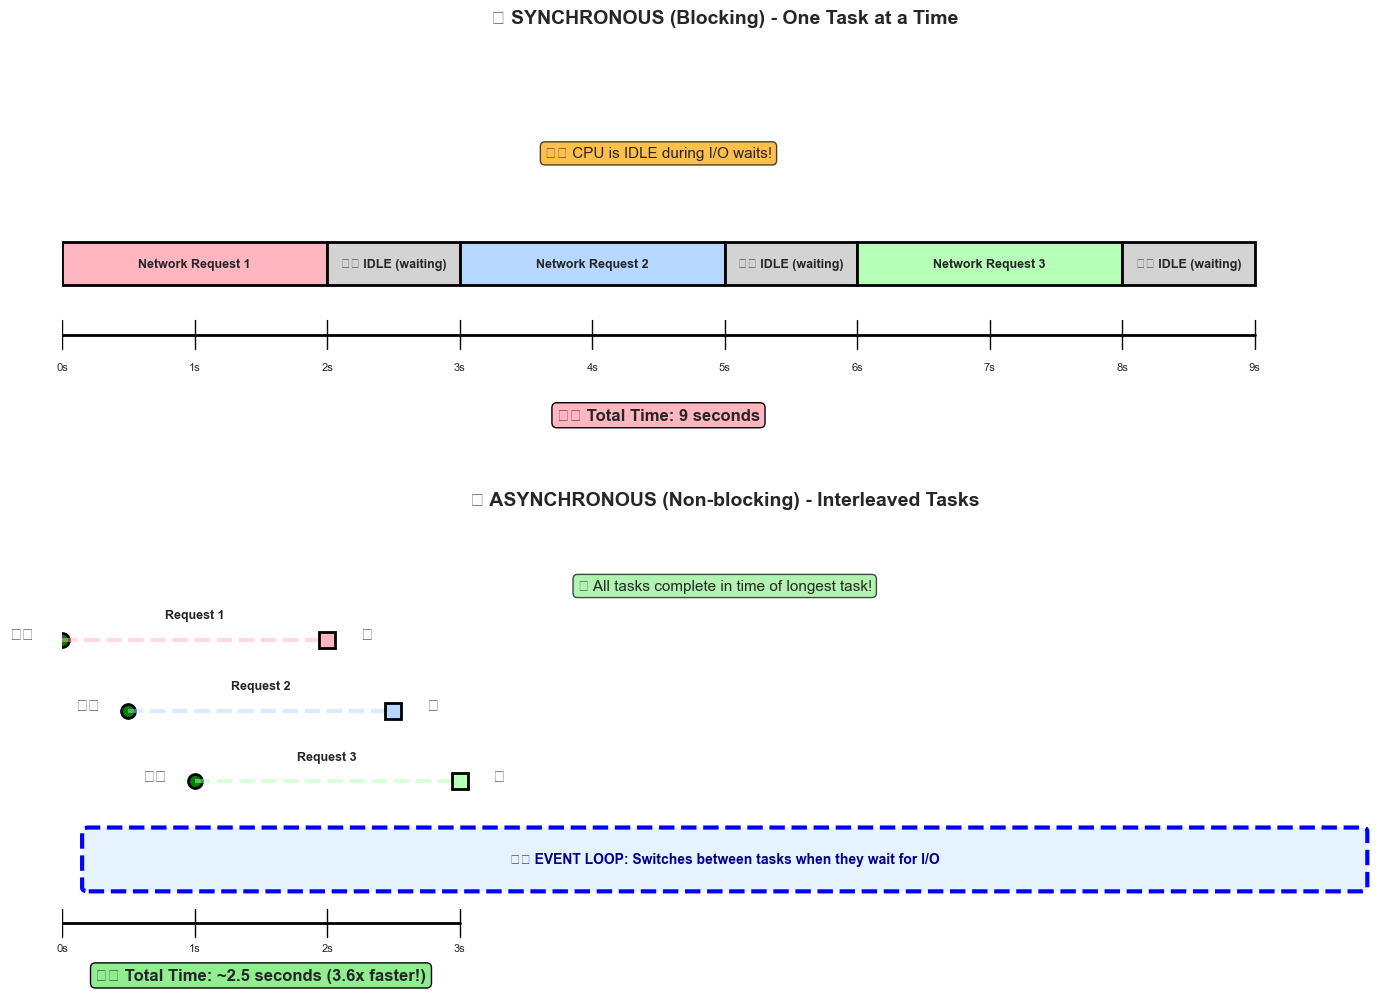


KEY DIFFERENCE:

SYNCHRONOUS (Traditional):
  - Executes tasks one after another
  - WAITS and does nothing during I/O
  - Simple but wasteful for I/O operations
  - Total time = Sum of all tasks

ASYNCHRONOUS (AsyncIO):
  - Starts multiple tasks
  - SWITCHES to other tasks during I/O waits
  - Efficient use of CPU time
  - Total time ≈ Longest task time

🎯 AsyncIO is like a skilled chef who starts multiple things
   cooking and manages them all efficiently!



In [4]:
# Visualization: Synchronous vs Asynchronous Execution

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

# SYNCHRONOUS EXECUTION
ax1.set_xlim(0, 10)
ax1.set_ylim(0, 6)
ax1.axis('off')
ax1.set_title('❌ SYNCHRONOUS (Blocking) - One Task at a Time', 
              fontsize=14, weight='bold', pad=20)

# Task blocks
tasks_sync = [
    ('Network Request 1', 0, 2, '#FFB6C1'),
    ('⏸️ IDLE (waiting)', 2, 1, '#D3D3D3'),
    ('Network Request 2', 3, 2, '#B6D7FF'),
    ('⏸️ IDLE (waiting)', 5, 1, '#D3D3D3'),
    ('Network Request 3', 6, 2, '#B6FFB6'),
    ('⏸️ IDLE (waiting)', 8, 1, '#D3D3D3')
]

y_pos = 3
for task, x_start, width, color in tasks_sync:
    rect = Rectangle((x_start, y_pos-0.3), width, 0.6,
                     facecolor=color, edgecolor='black', linewidth=2)
    ax1.add_patch(rect)
    ax1.text(x_start + width/2, y_pos, task, ha='center', va='center',
            fontsize=9, weight='bold')

# Timeline
ax1.plot([0, 9], [2, 2], 'k-', linewidth=2)
for i in range(10):
    ax1.plot([i, i], [1.8, 2.2], 'k-', linewidth=1)
    ax1.text(i, 1.5, f'{i}s', ha='center', fontsize=8)

ax1.text(4.5, 4.5, '⚠️ CPU is IDLE during I/O waits!', ha='center', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='orange', alpha=0.7))
ax1.text(4.5, 0.8, '⏱️ Total Time: 9 seconds', ha='center', fontsize=12,
        weight='bold', bbox=dict(boxstyle='round', facecolor='#FFB6C1'))

# ASYNCHRONOUS EXECUTION
ax2.set_xlim(0, 10)
ax2.set_ylim(0, 6)
ax2.axis('off')
ax2.set_title('✅ ASYNCHRONOUS (Non-blocking) - Interleaved Tasks', 
              fontsize=14, weight='bold', pad=20)

# Interleaved tasks
tasks_async = [
    ('Request 1', 0, 2, 4.5, '#FFB6C1'),
    ('Request 2', 0.5, 2, 3.5, '#B6D7FF'),
    ('Request 3', 1, 2, 2.5, '#B6FFB6'),
]

for task, x_start, width, y, color in tasks_async:
    # Start marker
    ax2.plot(x_start, y, 'o', markersize=10, color='green', markeredgecolor='black', 
            markeredgewidth=2)
    ax2.text(x_start-0.3, y, '▶️', ha='center', fontsize=12)
    
    # Waiting period (dashed line)
    ax2.plot([x_start, x_start+width], [y, y], '--', linewidth=3, color=color, alpha=0.5)
    
    # Completion marker
    ax2.plot(x_start+width, y, 's', markersize=12, color=color, 
            markeredgecolor='black', markeredgewidth=2)
    ax2.text(x_start+width+0.3, y, '✅', ha='center', fontsize=12)
    
    # Label
    ax2.text(x_start+width/2, y+0.3, task, ha='center', fontsize=9, weight='bold')

# Event loop working area
event_loop_box = FancyBboxPatch((0.2, 1), 9.6, 0.8, boxstyle="round,pad=0.05",
                                edgecolor='blue', facecolor='#E6F3FF', 
                                linewidth=3, linestyle='--')
ax2.add_patch(event_loop_box)
ax2.text(5, 1.4, '⚙️ EVENT LOOP: Switches between tasks when they wait for I/O',
        ha='center', va='center', fontsize=10, weight='bold', color='darkblue')

# Timeline
ax2.plot([0, 3], [0.5, 0.5], 'k-', linewidth=2)
for i in range(4):
    ax2.plot([i, i], [0.3, 0.7], 'k-', linewidth=1)
    ax2.text(i, 0.1, f'{i}s', ha='center', fontsize=8)

ax2.text(5, 5.2, '✅ All tasks complete in time of longest task!', ha='center',
        fontsize=11, bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.7))
ax2.text(1.5, -0.3, '⏱️ Total Time: ~2.5 seconds (3.6x faster!)', ha='center',
        fontsize=12, weight='bold', bbox=dict(boxstyle='round', facecolor='lightgreen'))

plt.tight_layout()
plt.show()

print("""
KEY DIFFERENCE:
===============

SYNCHRONOUS (Traditional):
  - Executes tasks one after another
  - WAITS and does nothing during I/O
  - Simple but wasteful for I/O operations
  - Total time = Sum of all tasks

ASYNCHRONOUS (AsyncIO):
  - Starts multiple tasks
  - SWITCHES to other tasks during I/O waits
  - Efficient use of CPU time
  - Total time ≈ Longest task time

🎯 AsyncIO is like a skilled chef who starts multiple things
   cooking and manages them all efficiently!
""")

## 2️⃣ The Event Loop: Heart of AsyncIO

### 🔄 What is an Event Loop?

The **Event Loop** is like a **traffic controller** at an airport:
- 🛫 Manages multiple planes (tasks)
- 📡 Monitors which plane is ready to land/take off
- ⚡ Gives runway time to ready planes
- ⏳ Doesn't wait for planes that aren't ready

### How It Works:

1. **Register** tasks with the event loop
2. Event loop **starts** tasks one by one
3. When a task **waits** (I/O operation), it **yields control**
4. Event loop **switches** to another ready task
5. When I/O completes, task becomes **ready** again
6. Event loop **resumes** the task

Let's visualize this!

C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\4134507017.py:96: UserWarning: Glyph 9881 (\N{GEAR}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\4134507017.py:96: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\4134507017.py:96: UserWarning: Glyph 128203 (\N{CLIPBOARD}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\4134507017.py:96: UserWarning: Glyph 9654 (\N{BLACK RIGHT-POINTING TRIANGLE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\4134507017.py:96: UserWarning: Glyph 9208 (\N{DOUBLE VERTICAL BAR}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\4134507017.py:96: UserWarning: Glyph 127760 (\N{GLOBE WITH MERIDIANS}) missing from font(s) Ari

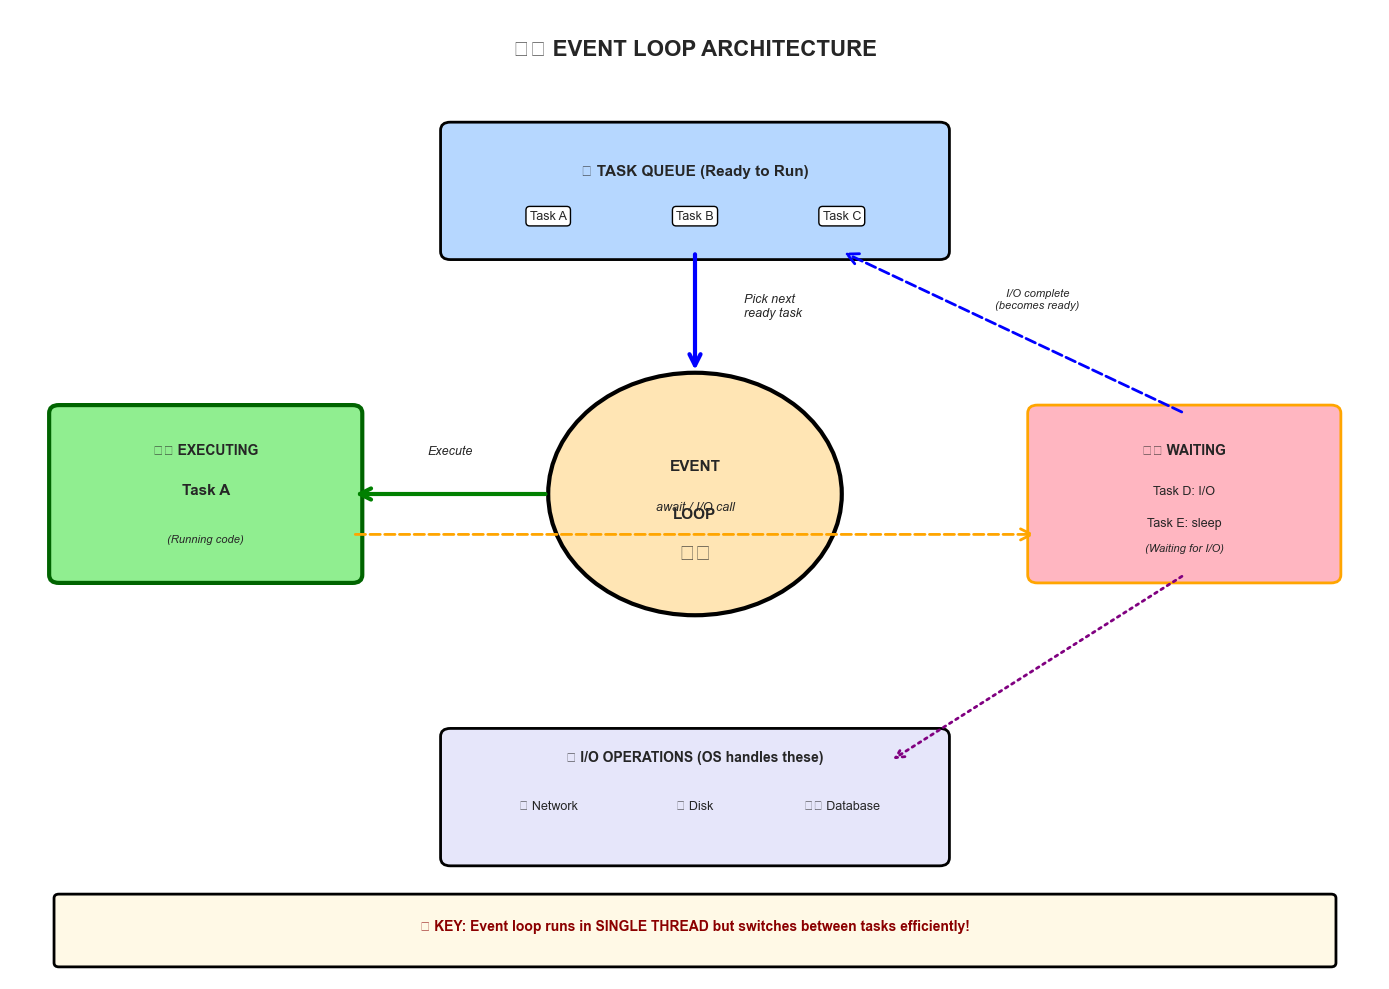


EVENT LOOP WORKFLOW:

1. 📋 Tasks are added to the QUEUE (ready to run)

2. ⚙️ EVENT LOOP picks a task from the queue

3. ▶️ Task EXECUTES until it hits an 'await' or I/O operation

4. ⏸️ Task YIELDS control and moves to WAITING state

5. 🌐 I/O operation happens (OS handles it in background)

6. ⚙️ Event loop switches to NEXT ready task from queue

7. 🔄 When I/O completes, task moves back to QUEUE

8. 🔁 REPEAT until all tasks are done

💡 The magic: While one task waits for I/O, others make progress!
   All in a SINGLE THREAD - no threading overhead!



In [5]:
# Visualization: Event Loop Architecture

fig, ax = plt.subplots(1, 1, figsize=(14, 10))
ax.set_xlim(0, 14)
ax.set_ylim(0, 12)
ax.axis('off')

# Title
ax.text(7, 11.5, '⚙️ EVENT LOOP ARCHITECTURE', ha='center', va='center',
        fontsize=16, weight='bold')

# Event Loop (center circle)
event_loop = Circle((7, 6), 1.5, facecolor='#FFE5B4', edgecolor='black', linewidth=3)
ax.add_patch(event_loop)
ax.text(7, 6.3, 'EVENT', ha='center', fontsize=11, weight='bold')
ax.text(7, 5.7, 'LOOP', ha='center', fontsize=11, weight='bold')
ax.text(7, 5.2, '⚙️', ha='center', fontsize=16)

# Task Queue (top)
queue_box = FancyBboxPatch((4.5, 9), 5, 1.5, boxstyle="round,pad=0.1",
                           edgecolor='black', facecolor='#B6D7FF', linewidth=2)
ax.add_patch(queue_box)
ax.text(7, 10, '📋 TASK QUEUE (Ready to Run)', ha='center', va='center',
        fontsize=11, weight='bold')
ax.text(5.5, 9.4, 'Task A', ha='center', fontsize=9,
        bbox=dict(boxstyle='round', facecolor='white'))
ax.text(7, 9.4, 'Task B', ha='center', fontsize=9,
        bbox=dict(boxstyle='round', facecolor='white'))
ax.text(8.5, 9.4, 'Task C', ha='center', fontsize=9,
        bbox=dict(boxstyle='round', facecolor='white'))

# Arrow from queue to event loop
arrow1 = FancyArrowPatch((7, 9), (7, 7.5), arrowstyle='->', mutation_scale=20,
                        linewidth=3, color='blue')
ax.add_patch(arrow1)
ax.text(7.5, 8.2, 'Pick next\nready task', ha='left', fontsize=9, style='italic')

# Currently Executing Task (left)
exec_box = FancyBboxPatch((0.5, 5), 3, 2, boxstyle="round,pad=0.1",
                         edgecolor='darkgreen', facecolor='#90EE90', linewidth=3)
ax.add_patch(exec_box)
ax.text(2, 6.5, '▶️ EXECUTING', ha='center', fontsize=10, weight='bold')
ax.text(2, 6, 'Task A', ha='center', fontsize=11, weight='bold')
ax.text(2, 5.4, '(Running code)', ha='center', fontsize=8, style='italic')

# Arrow from event loop to executing
arrow2 = FancyArrowPatch((5.5, 6), (3.5, 6), arrowstyle='->', mutation_scale=20,
                        linewidth=3, color='green')
ax.add_patch(arrow2)
ax.text(4.5, 6.5, 'Execute', ha='center', fontsize=9, style='italic')

# Waiting Tasks (right)
wait_box = FancyBboxPatch((10.5, 5), 3, 2, boxstyle="round,pad=0.1",
                         edgecolor='orange', facecolor='#FFB6C1', linewidth=2)
ax.add_patch(wait_box)
ax.text(12, 6.5, '⏸️ WAITING', ha='center', fontsize=10, weight='bold')
ax.text(12, 6, 'Task D: I/O', ha='center', fontsize=9)
ax.text(12, 5.6, 'Task E: sleep', ha='center', fontsize=9)
ax.text(12, 5.3, '(Waiting for I/O)', ha='center', fontsize=8, style='italic')

# Arrow from executing to waiting
arrow3 = FancyArrowPatch((3.5, 5.5), (10.5, 5.5), arrowstyle='->', mutation_scale=20,
                        linewidth=2, color='orange', linestyle='--')
ax.add_patch(arrow3)
ax.text(7, 5.8, 'await / I/O call', ha='center', fontsize=9, style='italic')

# Arrow from waiting back to queue
arrow4 = FancyArrowPatch((12, 7), (8.5, 9), arrowstyle='->', mutation_scale=20,
                        linewidth=2, color='blue', linestyle='--')
ax.add_patch(arrow4)
ax.text(10.5, 8.3, 'I/O complete\n(becomes ready)', ha='center', fontsize=8, 
        style='italic')

# I/O Operations (bottom)
io_box = FancyBboxPatch((4.5, 1.5), 5, 1.5, boxstyle="round,pad=0.1",
                       edgecolor='black', facecolor='#E6E6FA', linewidth=2)
ax.add_patch(io_box)
ax.text(7, 2.7, '🌐 I/O OPERATIONS (OS handles these)', ha='center', 
        fontsize=10, weight='bold')
ax.text(5.5, 2.1, '📡 Network', ha='center', fontsize=9)
ax.text(7, 2.1, '💾 Disk', ha='center', fontsize=9)
ax.text(8.5, 2.1, '🗄️ Database', ha='center', fontsize=9)

# Arrow from waiting to I/O
arrow5 = FancyArrowPatch((12, 5), (9, 2.7), arrowstyle='->', mutation_scale=15,
                        linewidth=2, color='purple', linestyle=':')
ax.add_patch(arrow5)

# Key components box
key_box = FancyBboxPatch((0.5, 0.2), 13, 0.8, boxstyle="round,pad=0.05",
                        edgecolor='black', facecolor='#FFF9E6', linewidth=2)
ax.add_patch(key_box)
ax.text(7, 0.6, '🔑 KEY: Event loop runs in SINGLE THREAD but switches between tasks efficiently!',
        ha='center', fontsize=10, weight='bold', color='darkred')

plt.tight_layout()
plt.show()

print("""
EVENT LOOP WORKFLOW:
====================

1. 📋 Tasks are added to the QUEUE (ready to run)

2. ⚙️ EVENT LOOP picks a task from the queue

3. ▶️ Task EXECUTES until it hits an 'await' or I/O operation

4. ⏸️ Task YIELDS control and moves to WAITING state

5. 🌐 I/O operation happens (OS handles it in background)

6. ⚙️ Event loop switches to NEXT ready task from queue

7. 🔄 When I/O completes, task moves back to QUEUE

8. 🔁 REPEAT until all tasks are done

💡 The magic: While one task waits for I/O, others make progress!
   All in a SINGLE THREAD - no threading overhead!
""")

## 3️⃣ Async/Await Syntax

### 📝 Basic Syntax

Python uses two keywords for async programming:

- **`async def`**: Defines an asynchronous function (coroutine)
- **`await`**: Pauses execution until async operation completes

```python
# Regular function (synchronous)
def regular_function():
    result = some_operation()  # Blocks until complete
    return result

# Async function (asynchronous)
async def async_function():
    result = await some_async_operation()  # Yields control while waiting
    return result
```

### 🎭 Key Terms:

- **Coroutine**: Function defined with `async def`
- **Awaitable**: Object that can be used with `await`
- **Task**: Wrapped coroutine scheduled to run on event loop
- **Future**: Placeholder for a result that will be available later

In [6]:
# Example 1: Basic Async Function

import asyncio

# Define an async function
async def say_hello(name, delay):
    """Simple async function that waits and prints a message"""
    print(f"⏳ Starting task for {name}...")
    await asyncio.sleep(delay)  # Simulate I/O operation (non-blocking!)
    print(f"✅ Hello, {name}! (waited {delay} seconds)")
    return f"Completed: {name}"

# You CANNOT call async functions directly like regular functions!
# This would NOT work: say_hello("Alice", 1)  ❌

# Method 1: Run a single coroutine
print("Method 1: Running single async function\n")
result = await say_hello("Alice", 1)
print(f"Result: {result}\n")

print("-" * 50 + "\n")

# Method 2: Run multiple coroutines concurrently
print("Method 2: Running multiple async functions concurrently\n")

# Create tasks
async def main():
    # Create tasks
    task1 = asyncio.create_task(say_hello("Bob", 2))
    task2 = asyncio.create_task(say_hello("Charlie", 1))
    task3 = asyncio.create_task(say_hello("David", 1.5))
    
    # Wait for all tasks to complete
    results = await asyncio.gather(task1, task2, task3)
    return results

# Run the main coroutine
start = time.time()
results = await main()
elapsed = time.time() - start

print(f"\n📊 Results: {results}")
print(f"⏱️ Total time: {elapsed:.2f} seconds")
print(f"💡 Notice: All tasks ran concurrently, not sequentially!")

Method 1: Running single async function

⏳ Starting task for Alice...
✅ Hello, Alice! (waited 1 seconds)
Result: Completed: Alice

--------------------------------------------------

Method 2: Running multiple async functions concurrently

⏳ Starting task for Bob...
⏳ Starting task for Charlie...
⏳ Starting task for David...
✅ Hello, Charlie! (waited 1 seconds)
✅ Hello, David! (waited 1.5 seconds)
✅ Hello, Bob! (waited 2 seconds)

📊 Results: ['Completed: Bob', 'Completed: Charlie', 'Completed: David']
⏱️ Total time: 2.01 seconds
💡 Notice: All tasks ran concurrently, not sequentially!


## 4️⃣ Visual Comparison: Threading vs AsyncIO vs Multiprocessing

Let's see the architectural differences!

C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\819170634.py:114: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\819170634.py:114: UserWarning: Glyph 8419 (\N{COMBINING ENCLOSING KEYCAP}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\819170634.py:114: UserWarning: Glyph 128274 (\N{LOCK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\819170634.py:114: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\819170634.py:114: UserWarning: Glyph 9881 (\N{GEAR}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\819170634.py:114: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) Arial.
  plt.tight

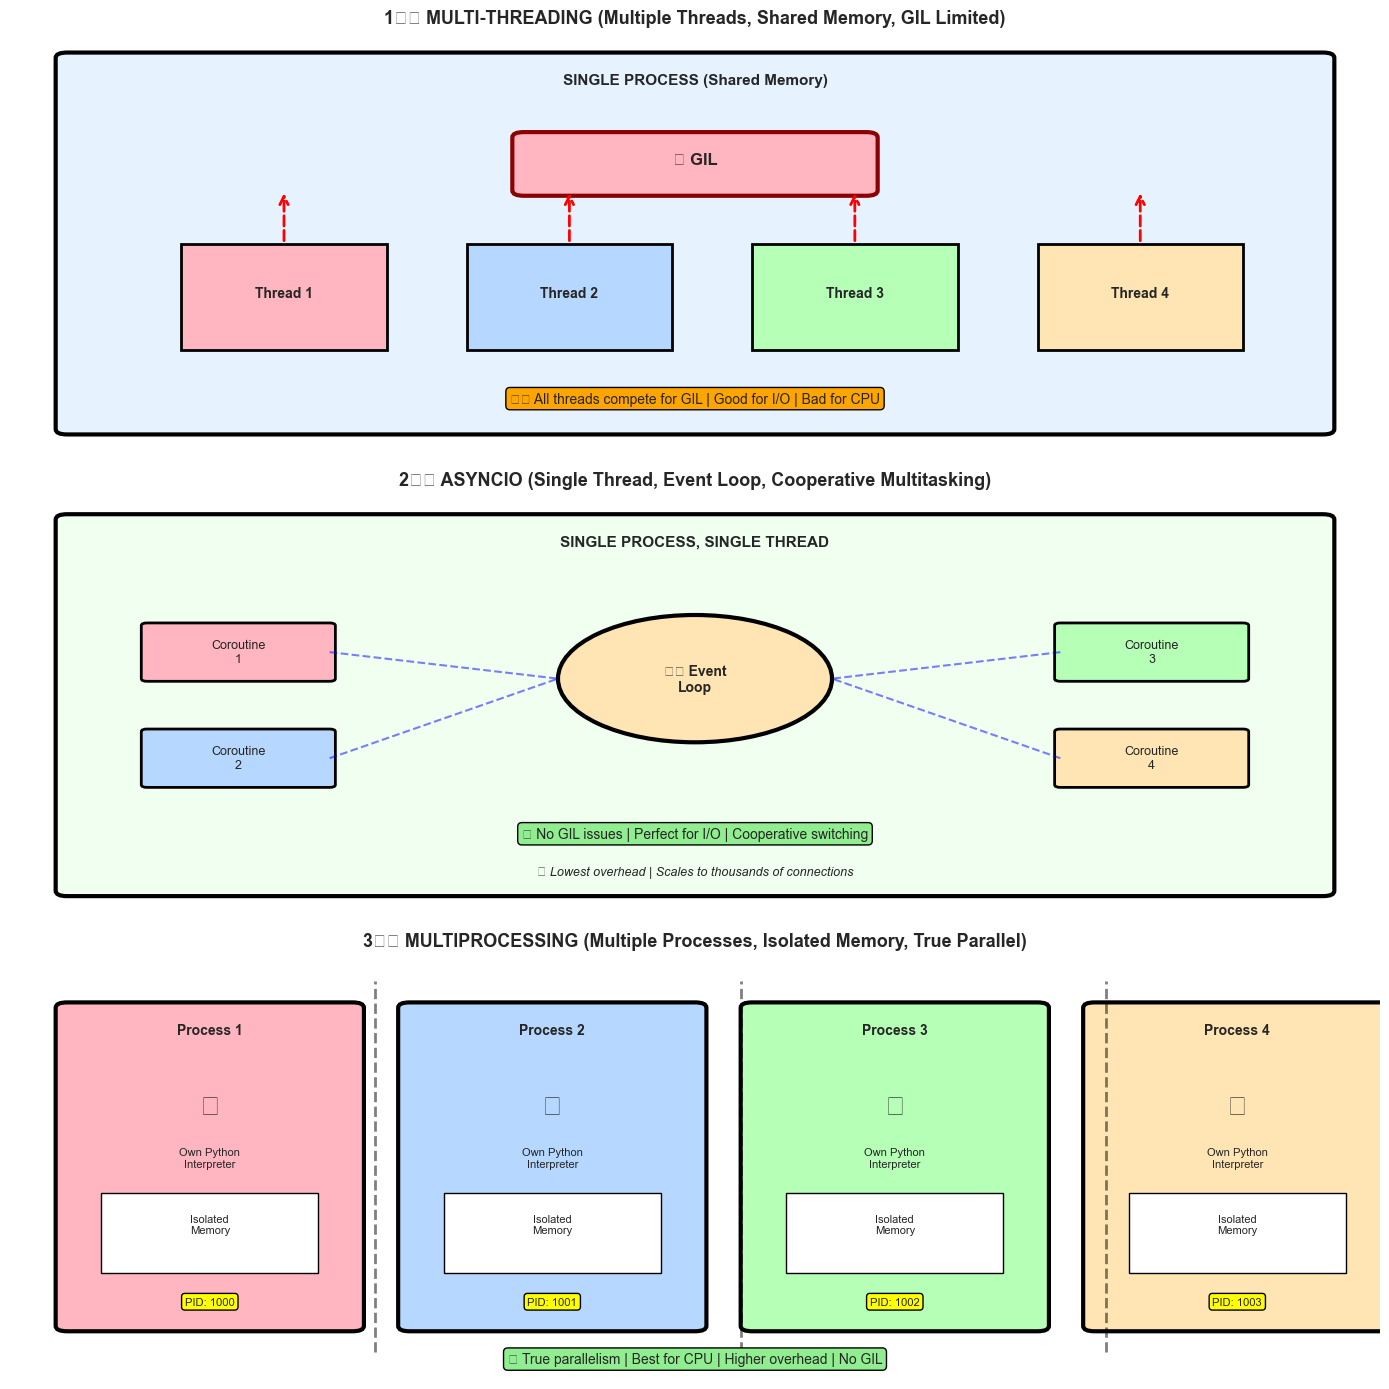


COMPARISON SUMMARY:

┌──────────────┬──────────────┬─────────────┬──────────────────┐
│ Feature      │ Threading    │ AsyncIO     │ Multiprocessing  │
├──────────────┼──────────────┼─────────────┼──────────────────┤
│ Concurrency  │ Yes          │ Yes         │ Yes              │
│ Parallelism  │ No (GIL)     │ No          │ Yes (True)       │
│ Memory       │ Shared       │ Shared      │ Isolated         │
│ Overhead     │ Medium       │ Low         │ High             │
│ Switching    │ Preemptive   │ Cooperative │ OS-managed       │
│ GIL Impact   │ Yes          │ No issue    │ No (bypassed)    │
│ Scale to     │ 100s         │ 1000s+      │ CPU cores        │
│ Best for     │ I/O tasks    │ I/O tasks   │ CPU tasks        │
│ Code change  │ Minimal      │ async/await │ Minimal          │
└──────────────┴──────────────┴─────────────┴──────────────────┘

🎯 FOR I/O-BOUND TASKS: AsyncIO > Threading > Multiprocessing
🎯 FOR CPU-BOUND TASKS: Multiprocessing > Threading ≈ Sequential



In [7]:
# Visualization: Threading vs AsyncIO vs Multiprocessing

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 14))

colors = ['#FFB6C1', '#B6D7FF', '#B6FFB6', '#FFE5B4']

# 1. THREADING
ax1.set_xlim(0, 12)
ax1.set_ylim(0, 8)
ax1.axis('off')
ax1.set_title('1️⃣ MULTI-THREADING (Multiple Threads, Shared Memory, GIL Limited)',
              fontsize=13, weight='bold')

# Process box
process_box = FancyBboxPatch((0.5, 0.5), 11, 7, boxstyle="round,pad=0.1",
                             edgecolor='black', facecolor='#E6F3FF', linewidth=3)
ax1.add_patch(process_box)
ax1.text(6, 7, 'SINGLE PROCESS (Shared Memory)', ha='center', fontsize=11, weight='bold')

# GIL Lock
gil_box = FancyBboxPatch((4.5, 5), 3, 1, boxstyle="round,pad=0.1",
                        edgecolor='darkred', facecolor='#FFB6C1', linewidth=3)
ax1.add_patch(gil_box)
ax1.text(6, 5.5, '🔒 GIL', ha='center', fontsize=12, weight='bold')

# Threads
for i in range(4):
    x_pos = 1.5 + i*2.5
    thread_box = Rectangle((x_pos, 2), 1.8, 2, edgecolor='black',
                           facecolor=colors[i], linewidth=2)
    ax1.add_patch(thread_box)
    ax1.text(x_pos+0.9, 3, f'Thread {i+1}', ha='center', fontsize=10, weight='bold')
    # Arrow to GIL
    arrow = FancyArrowPatch((x_pos+0.9, 4), (x_pos+0.9, 5), arrowstyle='->',
                           mutation_scale=15, linewidth=2, color='red', linestyle='--')
    ax1.add_patch(arrow)

ax1.text(6, 1, '⚠️ All threads compete for GIL | Good for I/O | Bad for CPU',
        ha='center', fontsize=10, bbox=dict(boxstyle='round', facecolor='orange'))

# 2. ASYNCIO
ax2.set_xlim(0, 12)
ax2.set_ylim(0, 8)
ax2.axis('off')
ax2.set_title('2️⃣ ASYNCIO (Single Thread, Event Loop, Cooperative Multitasking)',
              fontsize=13, weight='bold')

# Process box
process_box2 = FancyBboxPatch((0.5, 0.5), 11, 7, boxstyle="round,pad=0.1",
                              edgecolor='black', facecolor='#F0FFF0', linewidth=3)
ax2.add_patch(process_box2)
ax2.text(6, 7, 'SINGLE PROCESS, SINGLE THREAD', ha='center', fontsize=11, weight='bold')

# Event Loop (center)
event_loop = Circle((6, 4.5), 1.2, facecolor='#FFE5B4', edgecolor='black', linewidth=3)
ax2.add_patch(event_loop)
ax2.text(6, 4.5, '⚙️ Event\nLoop', ha='center', va='center', fontsize=10, weight='bold')

# Coroutines around event loop
coroutine_positions = [(2, 5), (2, 3), (10, 5), (10, 3)]
for i, (x, y) in enumerate(coroutine_positions):
    coroutine_box = FancyBboxPatch((x-0.8, y-0.5), 1.6, 1, boxstyle="round,pad=0.05",
                                   edgecolor='black', facecolor=colors[i], linewidth=2)
    ax2.add_patch(coroutine_box)
    ax2.text(x, y, f'Coroutine\n{i+1}', ha='center', va='center', fontsize=9)
    
    # Dashed line to event loop
    if x < 6:
        ax2.plot([x+0.8, 4.8], [y, 4.5], '--', linewidth=1.5, color='blue', alpha=0.5)
    else:
        ax2.plot([x-0.8, 7.2], [y, 4.5], '--', linewidth=1.5, color='blue', alpha=0.5)

ax2.text(6, 1.5, '✅ No GIL issues | Perfect for I/O | Cooperative switching',
        ha='center', fontsize=10, bbox=dict(boxstyle='round', facecolor='lightgreen'))
ax2.text(6, 0.8, '🎯 Lowest overhead | Scales to thousands of connections',
        ha='center', fontsize=9, style='italic')

# 3. MULTIPROCESSING
ax3.set_xlim(0, 12)
ax3.set_ylim(0, 8)
ax3.axis('off')
ax3.set_title('3️⃣ MULTIPROCESSING (Multiple Processes, Isolated Memory, True Parallel)',
              fontsize=13, weight='bold')

# Multiple processes
for i in range(4):
    x_pos = 0.5 + i*3
    process_box3 = FancyBboxPatch((x_pos, 1), 2.5, 6, boxstyle="round,pad=0.1",
                                  edgecolor='black', facecolor=colors[i], linewidth=3)
    ax3.add_patch(process_box3)
    ax3.text(x_pos+1.25, 6.5, f'Process {i+1}', ha='center', fontsize=10, weight='bold')
    
    # Python interpreter symbol
    ax3.text(x_pos+1.25, 5, '🐍', ha='center', fontsize=20)
    ax3.text(x_pos+1.25, 4, 'Own Python\nInterpreter', ha='center', fontsize=8)
    
    # Memory
    mem_box = Rectangle((x_pos+0.3, 2), 1.9, 1.5, edgecolor='black',
                        facecolor='white', linewidth=1)
    ax3.add_patch(mem_box)
    ax3.text(x_pos+1.25, 2.75, 'Isolated\nMemory', ha='center', fontsize=8)
    
    # PID
    ax3.text(x_pos+1.25, 1.4, f'PID: {1000+i}', ha='center', fontsize=8,
            bbox=dict(boxstyle='round', facecolor='yellow'))

# Barriers between processes
for x in [3.2, 6.4, 9.6]:
    ax3.plot([x, x], [0.5, 7.5], 'k--', linewidth=2, alpha=0.5)

ax3.text(6, 0.3, '✅ True parallelism | Best for CPU | Higher overhead | No GIL',
        ha='center', fontsize=10, bbox=dict(boxstyle='round', facecolor='lightgreen'))

plt.tight_layout()
plt.show()

print("""
COMPARISON SUMMARY:
===================

┌──────────────┬──────────────┬─────────────┬──────────────────┐
│ Feature      │ Threading    │ AsyncIO     │ Multiprocessing  │
├──────────────┼──────────────┼─────────────┼──────────────────┤
│ Concurrency  │ Yes          │ Yes         │ Yes              │
│ Parallelism  │ No (GIL)     │ No          │ Yes (True)       │
│ Memory       │ Shared       │ Shared      │ Isolated         │
│ Overhead     │ Medium       │ Low         │ High             │
│ Switching    │ Preemptive   │ Cooperative │ OS-managed       │
│ GIL Impact   │ Yes          │ No issue    │ No (bypassed)    │
│ Scale to     │ 100s         │ 1000s+      │ CPU cores        │
│ Best for     │ I/O tasks    │ I/O tasks   │ CPU tasks        │
│ Code change  │ Minimal      │ async/await │ Minimal          │
└──────────────┴──────────────┴─────────────┴──────────────────┘

🎯 FOR I/O-BOUND TASKS: AsyncIO > Threading > Multiprocessing
🎯 FOR CPU-BOUND TASKS: Multiprocessing > Threading ≈ Sequential
""")

## 5️⃣ Real Performance Test: Synchronous vs AsyncIO

Let's prove AsyncIO's performance with actual code! We'll simulate multiple I/O operations.

🔬 EXPERIMENT: 10 I/O operations (0.5s each)


1️⃣ SYNCHRONOUS (Sequential Execution)
------------------------------------------------------------
✅ Completed 10 tasks
⏱️  Time taken: 5.21 seconds
📊 Expected: 5.0s (sum of all waits)

2️⃣ MULTI-THREADING (ThreadPoolExecutor)
------------------------------------------------------------
✅ Completed 10 tasks
⏱️  Time taken: 1.30 seconds
📊 Speedup: 4.0x faster than sequential

3️⃣ ASYNCIO (Async/Await)
------------------------------------------------------------
✅ Completed 10 tasks
⏱️  Time taken: 0.51 seconds
📊 Speedup: 10.3x faster than sequential

📊 PERFORMANCE COMPARISON


C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\1122556616.py:95: UserWarning: Glyph 9889 (\N{HIGH VOLTAGE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9889 (\N{HIGH VOLTAGE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


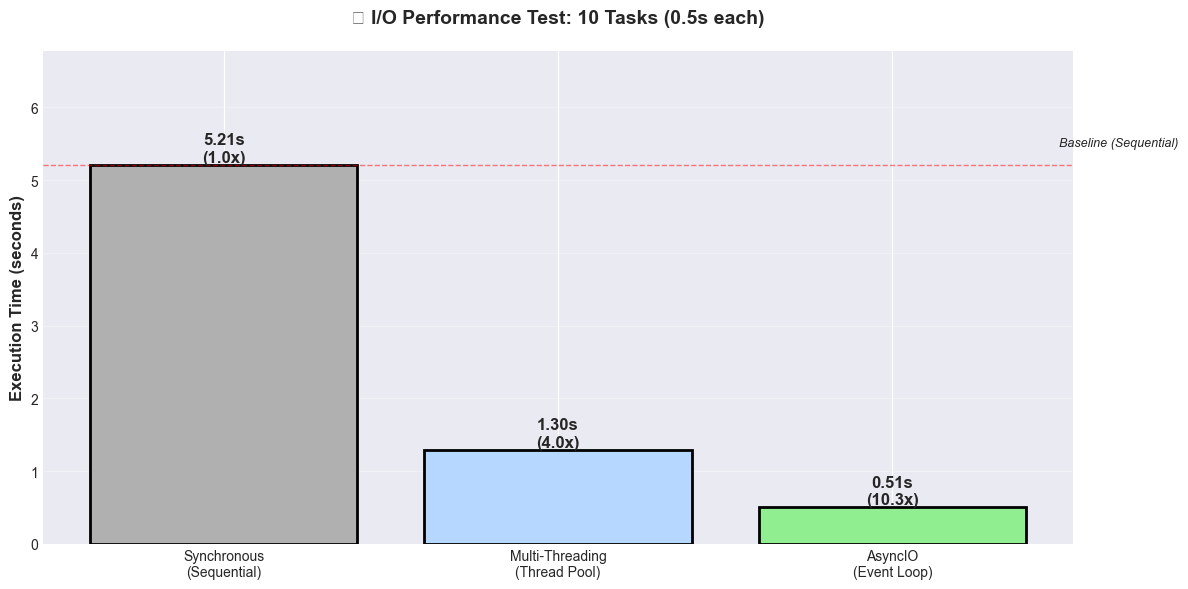


RESULTS SUMMARY:
Synchronous:   5.21s  (baseline - everything done sequentially)
Threading:     1.30s  (4.0x speedup)
AsyncIO:       0.51s  (10.3x speedup) ⭐ WINNER!

💡 KEY INSIGHTS:
- AsyncIO and Threading both provide similar speedups for I/O tasks
- AsyncIO has LOWER overhead (no thread creation/switching)
- AsyncIO scales better (can handle 1000s of concurrent operations)
- For 10 tasks, ideal time is ~0.5s (longest task)
- Actual time includes small overhead from task management



In [8]:
# Performance Comparison: Synchronous vs Threading vs AsyncIO

import asyncio
import time
from concurrent.futures import ThreadPoolExecutor

# Simulate I/O operation (network request, file read, etc.)
def sync_io_task(task_id):
    """Synchronous I/O task"""
    time.sleep(0.5)  # Simulate I/O wait (blocks!)
    return f"Task {task_id} completed"

async def async_io_task(task_id):
    """Asynchronous I/O task"""
    await asyncio.sleep(0.5)  # Simulate I/O wait (non-blocking!)
    return f"Task {task_id} completed"

# Number of tasks to perform
num_tasks = 10

print(f"🔬 EXPERIMENT: {num_tasks} I/O operations (0.5s each)\n")
print("=" * 60)

# 1. SYNCHRONOUS (Sequential)
print("\n1️⃣ SYNCHRONOUS (Sequential Execution)")
print("-" * 60)
start = time.time()
results = []
for i in range(num_tasks):
    result = sync_io_task(i)
    results.append(result)
sync_time = time.time() - start
print(f"✅ Completed {num_tasks} tasks")
print(f"⏱️  Time taken: {sync_time:.2f} seconds")
print(f"📊 Expected: {num_tasks * 0.5:.1f}s (sum of all waits)")

# 2. THREADING
print("\n2️⃣ MULTI-THREADING (ThreadPoolExecutor)")
print("-" * 60)
start = time.time()
with ThreadPoolExecutor(max_workers=num_tasks) as executor:
    results = list(executor.map(sync_io_task, range(num_tasks)))
threading_time = time.time() - start
print(f"✅ Completed {num_tasks} tasks")
print(f"⏱️  Time taken: {threading_time:.2f} seconds")
print(f"📊 Speedup: {sync_time/threading_time:.1f}x faster than sequential")

# 3. ASYNCIO
print("\n3️⃣ ASYNCIO (Async/Await)")
print("-" * 60)

async def run_async_tasks():
    tasks = [async_io_task(i) for i in range(num_tasks)]
    return await asyncio.gather(*tasks)

start = time.time()
results = await run_async_tasks()
asyncio_time = time.time() - start
print(f"✅ Completed {num_tasks} tasks")
print(f"⏱️  Time taken: {asyncio_time:.2f} seconds")
print(f"📊 Speedup: {sync_time/asyncio_time:.1f}x faster than sequential")

# Visualize results
print("\n" + "=" * 60)
print("📊 PERFORMANCE COMPARISON")
print("=" * 60)

fig, ax = plt.subplots(figsize=(12, 6))

methods = ['Synchronous\n(Sequential)', 'Multi-Threading\n(Thread Pool)', 
           'AsyncIO\n(Event Loop)']
times = [sync_time, threading_time, asyncio_time]
colors = ['#B0B0B0', '#B6D7FF', '#90EE90']

bars = ax.bar(methods, times, color=colors, edgecolor='black', linewidth=2)

# Add value labels on bars
for i, (bar, time_val) in enumerate(zip(bars, times)):
    height = bar.get_height()
    speedup = sync_time / time_val
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{time_val:.2f}s\n({speedup:.1f}x)',
            ha='center', va='bottom', fontsize=12, weight='bold')

ax.set_ylabel('Execution Time (seconds)', fontsize=12, weight='bold')
ax.set_title(f'⚡ I/O Performance Test: {num_tasks} Tasks (0.5s each)',
            fontsize=14, weight='bold', pad=20)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, max(times) * 1.3)

# Add baseline line
ax.axhline(y=sync_time, color='red', linestyle='--', linewidth=1, alpha=0.5)
ax.text(2.5, sync_time * 1.05, 'Baseline (Sequential)', fontsize=9, style='italic')

plt.tight_layout()
plt.show()

print(f"""
RESULTS SUMMARY:
================
Synchronous:   {sync_time:.2f}s  (baseline - everything done sequentially)
Threading:     {threading_time:.2f}s  ({sync_time/threading_time:.1f}x speedup)
AsyncIO:       {asyncio_time:.2f}s  ({sync_time/asyncio_time:.1f}x speedup) ⭐ WINNER!

💡 KEY INSIGHTS:
- AsyncIO and Threading both provide similar speedups for I/O tasks
- AsyncIO has LOWER overhead (no thread creation/switching)
- AsyncIO scales better (can handle 1000s of concurrent operations)
- For {num_tasks} tasks, ideal time is ~0.5s (longest task)
- Actual time includes small overhead from task management
""")

## 6️⃣ Real-World Example: Web Scraping

Let's see AsyncIO in action with a practical example - fetching multiple web pages!

🌐 Fetching 5 URLs (each has 1s server delay)

1️⃣ SYNCHRONOUS VERSION (requests library)
------------------------------------------------------------
✓ Fetched 364 bytes from https://httpbin.org/delay/1
✓ Fetched 364 bytes from https://httpbin.org/delay/1
✓ Fetched 364 bytes from https://httpbin.org/delay/1
✓ Fetched 364 bytes from https://httpbin.org/delay/1
✓ Fetched 364 bytes from https://httpbin.org/delay/1

⏱️  Total time: 11.47 seconds

2️⃣ ASYNCHRONOUS VERSION (aiohttp library)
------------------------------------------------------------
✓ Fetched 368 bytes from https://httpbin.org/delay/1
✓ Fetched 368 bytes from https://httpbin.org/delay/1
✓ Fetched 368 bytes from https://httpbin.org/delay/1
✓ Fetched 368 bytes from https://httpbin.org/delay/1
✓ Fetched 368 bytes from https://httpbin.org/delay/1

⏱️  Total time: 2.00 seconds



C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\3797266579.py:77: UserWarning: Glyph 127760 (\N{GLOBE WITH MERIDIANS}) missing from font(s) Arial.
  plt.tight_layout()


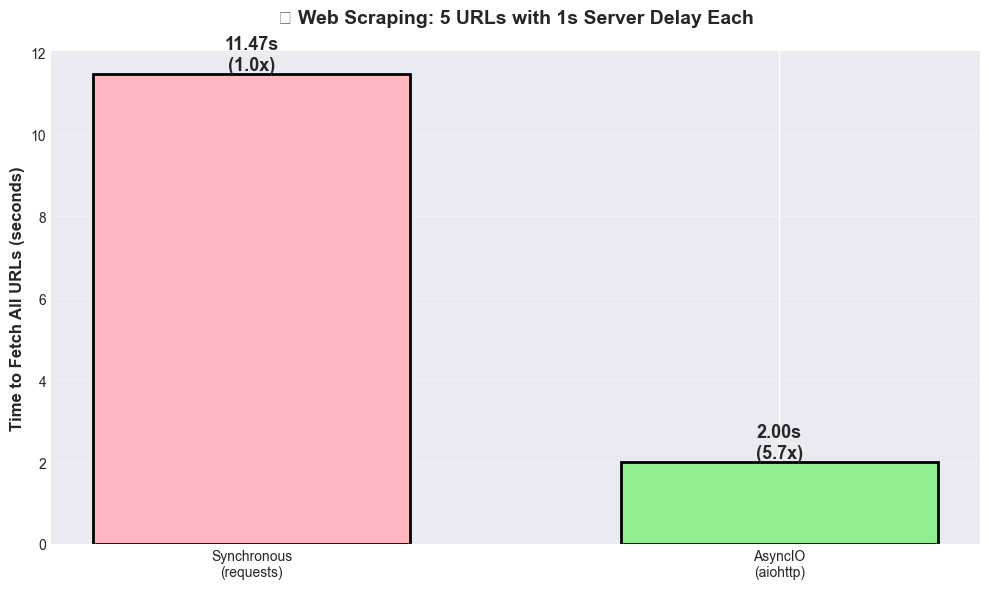


WEB SCRAPING RESULTS:
Synchronous (requests):  11.47s  (waits for each request)
AsyncIO (aiohttp):       2.00s  (5.7x faster!)

💡 REAL-WORLD IMPACT:
- Scraping 100 websites: ~100s vs ~1-2s
- API calls: Massive improvement for multiple endpoints
- Database queries: Concurrent queries complete faster
- File operations: Read/write multiple files simultaneously

🎯 AsyncIO shines when you have many I/O operations!



In [9]:
# Real-World Example: Async Web Requests

# Test URLs (using httpbin.org - a public HTTP testing service)
urls = [
    "https://httpbin.org/delay/1",  # Simulates 1 second delay
    "https://httpbin.org/delay/1",
    "https://httpbin.org/delay/1",
    "https://httpbin.org/delay/1",
    "https://httpbin.org/delay/1",
]

print(f"🌐 Fetching {len(urls)} URLs (each has 1s server delay)\n")

# SYNCHRONOUS VERSION (using requests)
print("1️⃣ SYNCHRONOUS VERSION (requests library)")
print("-" * 60)

import requests

def fetch_sync(url):
    """Synchronous HTTP request"""
    response = requests.get(url)
    return len(response.content)

start = time.time()
for url in urls:
    size = fetch_sync(url)
    print(f"✓ Fetched {size} bytes from {url}")
sync_web_time = time.time() - start
print(f"\n⏱️  Total time: {sync_web_time:.2f} seconds\n")

# ASYNCHRONOUS VERSION (using aiohttp)
print("2️⃣ ASYNCHRONOUS VERSION (aiohttp library)")
print("-" * 60)

async def fetch_async(session, url):
    """Asynchronous HTTP request"""
    async with session.get(url) as response:
        content = await response.read()
        return len(content)

async def fetch_all_async(urls):
    """Fetch all URLs concurrently"""
    async with aiohttp.ClientSession() as session:
        tasks = [fetch_async(session, url) for url in urls]
        results = await asyncio.gather(*tasks)
        return results

start = time.time()
sizes = await fetch_all_async(urls)
for url, size in zip(urls, sizes):
    print(f"✓ Fetched {size} bytes from {url}")
async_web_time = time.time() - start
print(f"\n⏱️  Total time: {async_web_time:.2f} seconds\n")

# Comparison Chart
fig, ax = plt.subplots(figsize=(10, 6))

methods = ['Synchronous\n(requests)', 'AsyncIO\n(aiohttp)']
times = [sync_web_time, async_web_time]
colors = ['#FFB6C1', '#90EE90']

bars = ax.bar(methods, times, color=colors, edgecolor='black', linewidth=2, width=0.6)

for i, (bar, time_val) in enumerate(zip(bars, times)):
    height = bar.get_height()
    speedup = sync_web_time / time_val
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{time_val:.2f}s\n({speedup:.1f}x)',
            ha='center', va='bottom', fontsize=13, weight='bold')

ax.set_ylabel('Time to Fetch All URLs (seconds)', fontsize=12, weight='bold')
ax.set_title(f'🌐 Web Scraping: {len(urls)} URLs with 1s Server Delay Each',
            fontsize=14, weight='bold', pad=20)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"""
WEB SCRAPING RESULTS:
=====================
Synchronous (requests):  {sync_web_time:.2f}s  (waits for each request)
AsyncIO (aiohttp):       {async_web_time:.2f}s  ({sync_web_time/async_web_time:.1f}x faster!)

💡 REAL-WORLD IMPACT:
- Scraping 100 websites: ~100s vs ~1-2s
- API calls: Massive improvement for multiple endpoints
- Database queries: Concurrent queries complete faster
- File operations: Read/write multiple files simultaneously

🎯 AsyncIO shines when you have many I/O operations!
""")

## 7️⃣ Common AsyncIO Patterns

Let's learn essential async patterns you'll use every day!

In [10]:
# Common AsyncIO Patterns

print("📚 ESSENTIAL ASYNCIO PATTERNS\n")
print("=" * 70)

# Pattern 1: Running tasks concurrently with asyncio.gather()
print("\n1️⃣ PATTERN: asyncio.gather() - Run multiple tasks concurrently")
print("-" * 70)

async def task_a():
    await asyncio.sleep(1)
    return "Task A result"

async def task_b():
    await asyncio.sleep(1)
    return "Task B result"

async def task_c():
    await asyncio.sleep(1)
    return "Task C result"

# All tasks run concurrently
start = time.time()
results = await asyncio.gather(task_a(), task_b(), task_c())
elapsed = time.time() - start

print(f"Results: {results}")
print(f"Time: {elapsed:.2f}s (all run concurrently!)")

# Pattern 2: Creating tasks explicitly
print("\n2️⃣ PATTERN: asyncio.create_task() - Create and manage tasks")
print("-" * 70)

async def long_operation(name, duration):
    print(f"  ▶️  {name} started")
    await asyncio.sleep(duration)
    print(f"  ✅ {name} completed")
    return f"{name} done"

start = time.time()
# Create tasks
task1 = asyncio.create_task(long_operation("Operation 1", 1))
task2 = asyncio.create_task(long_operation("Operation 2", 0.5))
task3 = asyncio.create_task(long_operation("Operation 3", 0.8))

# Tasks are now running in the background!
print("All tasks created and running...")

# Wait for all to complete
results = await asyncio.gather(task1, task2, task3)
elapsed = time.time() - start
print(f"Time: {elapsed:.2f}s\n")

# Pattern 3: Timeout handling
print("\n3️⃣ PATTERN: asyncio.wait_for() - Timeout protection")
print("-" * 70)

async def slow_operation():
    await asyncio.sleep(5)
    return "Completed"

try:
    result = await asyncio.wait_for(slow_operation(), timeout=2.0)
    print(f"Result: {result}")
except asyncio.TimeoutError:
    print("⚠️  Operation timed out after 2 seconds!")

# Pattern 4: Running synchronous code in async context
print("\n4️⃣ PATTERN: asyncio.to_thread() - Run blocking code async")
print("-" * 70)

import time as time_module

def blocking_function(name):
    """This is a blocking function (uses time.sleep)"""
    time_module.sleep(1)
    return f"Blocking {name} completed"

# Run blocking functions concurrently using threads
start = time.time()
results = await asyncio.gather(
    asyncio.to_thread(blocking_function, "A"),
    asyncio.to_thread(blocking_function, "B"),
    asyncio.to_thread(blocking_function, "C")
)
elapsed = time.time() - start
print(f"Results: {results}")
print(f"Time: {elapsed:.2f}s (blocking code ran concurrently!)")

# Pattern 5: Error handling
print("\n5️⃣ PATTERN: Error handling with gather(return_exceptions=True)")
print("-" * 70)

async def task_success():
    await asyncio.sleep(0.5)
    return "Success!"

async def task_failure():
    await asyncio.sleep(0.5)
    raise ValueError("Task failed!")

# Without return_exceptions, first exception stops everything
# With return_exceptions=True, all tasks complete and exceptions are returned
results = await asyncio.gather(
    task_success(),
    task_failure(),
    task_success(),
    return_exceptions=True
)

for i, result in enumerate(results):
    if isinstance(result, Exception):
        print(f"  Task {i}: ❌ {result}")
    else:
        print(f"  Task {i}: ✅ {result}")

print("\n" + "=" * 70)
print("✅ All patterns demonstrated!")

📚 ESSENTIAL ASYNCIO PATTERNS


1️⃣ PATTERN: asyncio.gather() - Run multiple tasks concurrently
----------------------------------------------------------------------
Results: ['Task A result', 'Task B result', 'Task C result']
Time: 1.00s (all run concurrently!)

2️⃣ PATTERN: asyncio.create_task() - Create and manage tasks
----------------------------------------------------------------------
All tasks created and running...
  ▶️  Operation 1 started
  ▶️  Operation 2 started
  ▶️  Operation 3 started
  ✅ Operation 2 completed
  ✅ Operation 3 completed
  ✅ Operation 1 completed
Time: 1.01s


3️⃣ PATTERN: asyncio.wait_for() - Timeout protection
----------------------------------------------------------------------
⚠️  Operation timed out after 2 seconds!

4️⃣ PATTERN: asyncio.to_thread() - Run blocking code async
----------------------------------------------------------------------
Results: ['Blocking A completed', 'Blocking B completed', 'Blocking C completed']
Time: 1.02s (blocking c

## 8️⃣ Execution Flow Visualization

Let's visualize how async code executes step-by-step!

C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\383204798.py:104: UserWarning: Glyph 9201 (\N{STOPWATCH}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\383204798.py:104: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\383204798.py:104: UserWarning: Glyph 9208 (\N{DOUBLE VERTICAL BAR}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\383204798.py:104: UserWarning: Glyph 9654 (\N{BLACK RIGHT-POINTING TRIANGLE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\383204798.py:104: UserWarning: Glyph 128260 (\N{ANTICLOCKWISE DOWNWARDS AND UPWARDS OPEN CIRCLE ARROWS}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\383204798.py:104: UserWarning: Glyph 9989 (\N

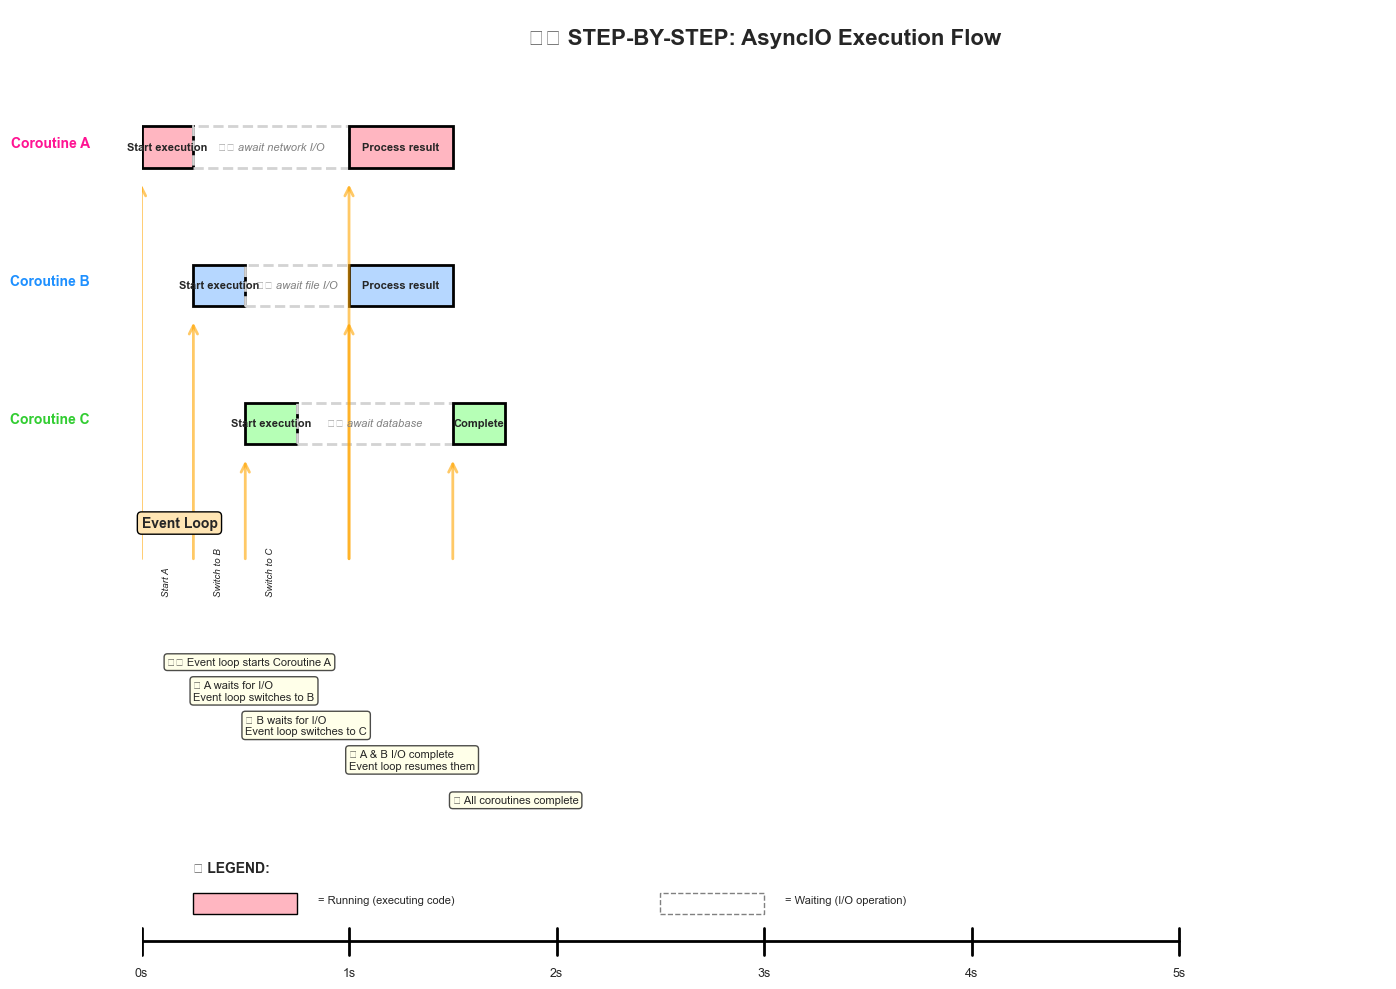


EXECUTION FLOW EXPLANATION:

Time 0.0s:  Event loop starts Coroutine A
            A runs until it hits 'await' (network I/O)

Time 0.5s:  A is waiting for network
            Event loop switches to Coroutine B
            B runs until it hits 'await' (file I/O)

Time 1.0s:  B is waiting for file I/O
            Event loop switches to Coroutine C
            C runs until it hits 'await' (database)

Time 2.0s:  A's network I/O completes → A resumes
            B's file I/O completes → B resumes
            Both A and B can continue processing

Time 3.0s:  C's database operation completes → C resumes
            All coroutines complete!

💡 KEY INSIGHT:
While one coroutine waits for I/O, others make progress!
The event loop efficiently manages all of them in a SINGLE THREAD.
No time wasted waiting - total time ≈ longest I/O operation!



In [11]:
# Visualization: Step-by-Step Async Execution

fig, ax = plt.subplots(figsize=(14, 10))
ax.set_xlim(0, 12)
ax.set_ylim(0, 14)
ax.axis('off')

ax.text(6, 13.5, '⏱️ STEP-BY-STEP: AsyncIO Execution Flow', 
        ha='center', fontsize=16, weight='bold')

# Timeline at the bottom
for i in range(6):
    ax.plot([i*2, i*2], [0.3, 0.7], 'k-', linewidth=2)
    ax.text(i*2, 0, f'{i}s', ha='center', fontsize=9)
ax.plot([0, 10], [0.5, 0.5], 'k-', linewidth=2)

# Define execution steps with timing
steps = [
    # (time_start, duration, coroutine, y_pos, color, status, description)
    (0, 0.5, 'Coroutine A', 12, '#FFB6C1', 'run', 'Start execution'),
    (0.5, 1.5, 'Coroutine A', 12, '#D3D3D3', 'wait', 'await network I/O'),
    (2, 1, 'Coroutine A', 12, '#FFB6C1', 'run', 'Process result'),
    
    (0.5, 0.5, 'Coroutine B', 10, '#B6D7FF', 'run', 'Start execution'),
    (1, 1, 'Coroutine B', 10, '#D3D3D3', 'wait', 'await file I/O'),
    (2, 1, 'Coroutine B', 10, '#B6D7FF', 'run', 'Process result'),
    
    (1, 0.5, 'Coroutine C', 8, '#B6FFB6', 'run', 'Start execution'),
    (1.5, 1.5, 'Coroutine C', 8, '#D3D3D3', 'wait', 'await database'),
    (3, 0.5, 'Coroutine C', 8, '#B6FFB6', 'run', 'Complete'),
]

# Draw execution blocks
for time_start, duration, name, y_pos, color, status, desc in steps:
    if status == 'run':
        # Running state - solid
        rect = Rectangle((time_start, y_pos-0.3), duration, 0.6,
                         facecolor=color, edgecolor='black', linewidth=2)
        ax.add_patch(rect)
        ax.text(time_start + duration/2, y_pos, desc, ha='center', 
               va='center', fontsize=8, weight='bold')
    else:
        # Waiting state - dashed outline
        rect = Rectangle((time_start, y_pos-0.3), duration, 0.6,
                         facecolor='white', edgecolor=color, linewidth=2, 
                         linestyle='--', fill=False)
        ax.add_patch(rect)
        ax.text(time_start + duration/2, y_pos, f'⏸️ {desc}', ha='center',
               va='center', fontsize=8, style='italic', color='gray')

# Coroutine labels
ax.text(-0.5, 12, 'Coroutine A', ha='right', fontsize=10, weight='bold', color='#FF1493')
ax.text(-0.5, 10, 'Coroutine B', ha='right', fontsize=10, weight='bold', color='#1E90FF')
ax.text(-0.5, 8, 'Coroutine C', ha='right', fontsize=10, weight='bold', color='#32CD32')

# Event loop activity
event_loop_y = 6
ax.text(0, event_loop_y+0.5, 'Event Loop', ha='left', fontsize=10, weight='bold',
        bbox=dict(boxstyle='round', facecolor='#FFE5B4'))

# Show event loop switching
switches = [
    (0, 12, 'Start A'),
    (0.5, 10, 'Switch to B'),
    (1, 8, 'Switch to C'),
    (2, 12, 'Resume A'),
    (2, 10, 'Resume B'),
    (3, 8, 'Resume C'),
]

for i, (t, from_y, label) in enumerate(switches):
    # Arrow from event loop to coroutine
    arrow = FancyArrowPatch((t, event_loop_y), (t, from_y-0.5),
                           arrowstyle='->', mutation_scale=15, linewidth=2,
                           color='orange', alpha=0.6)
    ax.add_patch(arrow)
    if i < 3:
        ax.text(t+0.2, event_loop_y-0.5, label, fontsize=7, style='italic',
               rotation=90, va='bottom')

# Add timeline annotations
timeline_annotations = [
    (0.25, 4.5, '▶️ Event loop starts Coroutine A'),
    (0.5, 4, '🔄 A waits for I/O\nEvent loop switches to B'),
    (1, 3.5, '🔄 B waits for I/O\nEvent loop switches to C'),
    (2, 3, '🔄 A & B I/O complete\nEvent loop resumes them'),
    (3, 2.5, '✅ All coroutines complete'),
]

for x, y, text in timeline_annotations:
    ax.text(x, y, text, fontsize=8, ha='left',
           bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.7))

# Legend
legend_y = 1
ax.text(0.5, legend_y+0.5, '🎨 LEGEND:', fontsize=10, weight='bold')
ax.add_patch(Rectangle((0.5, legend_y-0.1), 1, 0.3, facecolor='#FFB6C1', 
                       edgecolor='black', linewidth=1))
ax.text(1.7, legend_y+0.05, '= Running (executing code)', ha='left', fontsize=8)
ax.add_patch(Rectangle((5, legend_y-0.1), 1, 0.3, facecolor='white',
                       edgecolor='gray', linewidth=1, linestyle='--', fill=False))
ax.text(6.2, legend_y+0.05, '= Waiting (I/O operation)', ha='left', fontsize=8)

plt.tight_layout()
plt.show()

print("""
EXECUTION FLOW EXPLANATION:
===========================

Time 0.0s:  Event loop starts Coroutine A
            A runs until it hits 'await' (network I/O)
            
Time 0.5s:  A is waiting for network
            Event loop switches to Coroutine B
            B runs until it hits 'await' (file I/O)
            
Time 1.0s:  B is waiting for file I/O
            Event loop switches to Coroutine C
            C runs until it hits 'await' (database)
            
Time 2.0s:  A's network I/O completes → A resumes
            B's file I/O completes → B resumes
            Both A and B can continue processing
            
Time 3.0s:  C's database operation completes → C resumes
            All coroutines complete!

💡 KEY INSIGHT:
While one coroutine waits for I/O, others make progress!
The event loop efficiently manages all of them in a SINGLE THREAD.
No time wasted waiting - total time ≈ longest I/O operation!
""")

## 9️⃣ When to Use AsyncIO: Decision Guide

C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\3810564098.py:101: UserWarning: Glyph 129300 (\N{THINKING FACE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\3810564098.py:101: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\3810564098.py:101: UserWarning: Glyph 127760 (\N{GLOBE WITH MERIDIANS}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\3810564098.py:101: UserWarning: Glyph 128225 (\N{SATELLITE ANTENNA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\3810564098.py:101: UserWarning: Glyph 128452 (\N{FILE CABINET}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Amit.Malik\AppData\Local\Temp\ipykernel_36036\3810564098.py:101: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing fro

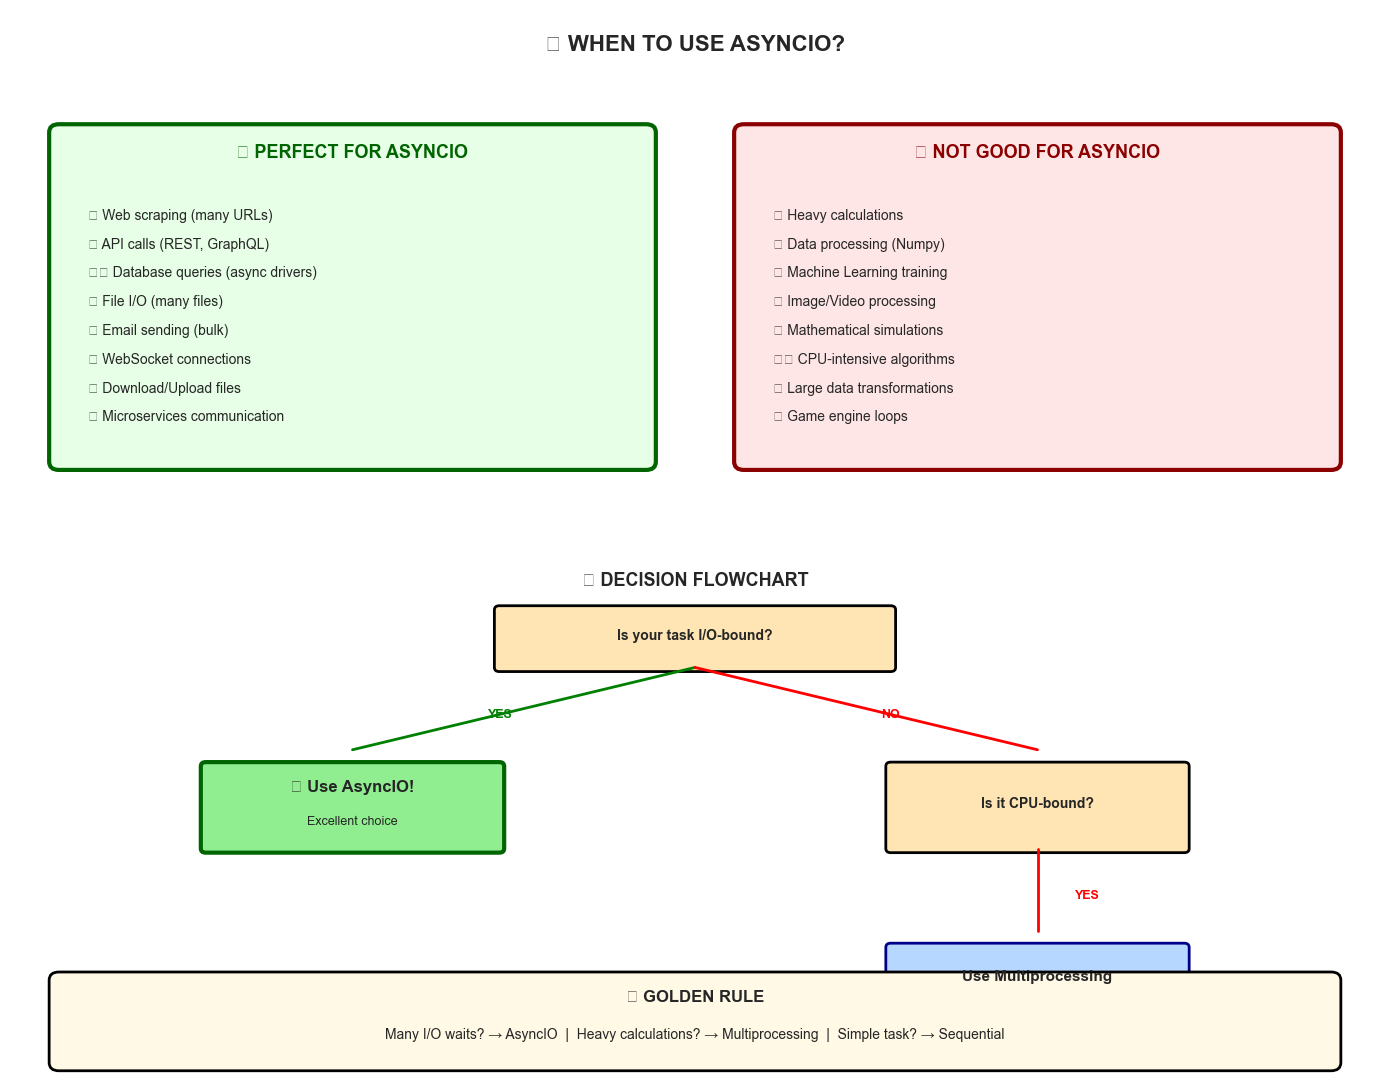


QUICK REFERENCE TABLE:

┌─────────────────────┬──────────────┬─────────────────────────┐
│ Scenario            │ Best Choice  │ Why?                    │
├─────────────────────┼──────────────┼─────────────────────────┤
│ 100 API calls       │ AsyncIO ⭐   │ Concurrent I/O          │
│ Web scraping        │ AsyncIO ⭐   │ Many network requests   │
│ Database queries    │ AsyncIO      │ I/O-bound operations    │
│ File processing     │ AsyncIO      │ Disk I/O waits          │
│ Image processing    │ Multi-Proc   │ CPU-intensive           │
│ Data analysis       │ Multi-Proc   │ Heavy computation       │
│ ML model training   │ Multi-Proc   │ CPU-bound               │
│ WebSocket server    │ AsyncIO ⭐   │ Many concurrent clients │
│ Simple script       │ Sequential   │ No need for complexity  │
└─────────────────────┴──────────────┴─────────────────────────┘

⭐ = AsyncIO is the clear winner!



In [12]:
# Decision Guide: When to Use AsyncIO

fig, ax = plt.subplots(figsize=(14, 11))
ax.set_xlim(0, 14)
ax.set_ylim(0, 13)
ax.axis('off')

ax.text(7, 12.5, '🤔 WHEN TO USE ASYNCIO?', ha='center', fontsize=16, weight='bold')

# Use Cases - Good for AsyncIO
good_box = FancyBboxPatch((0.5, 7.5), 6, 4, boxstyle="round,pad=0.1",
                          edgecolor='darkgreen', facecolor='#E6FFE6', linewidth=3)
ax.add_patch(good_box)
ax.text(3.5, 11.2, '✅ PERFECT FOR ASYNCIO', ha='center', fontsize=13, 
        weight='bold', color='darkgreen')

good_cases = [
    '🌐 Web scraping (many URLs)',
    '📡 API calls (REST, GraphQL)',
    '🗄️ Database queries (async drivers)',
    '💾 File I/O (many files)',
    '📧 Email sending (bulk)',
    '🔌 WebSocket connections',
    '📥 Download/Upload files',
    '⚡ Microservices communication',
]

for i, case in enumerate(good_cases):
    y = 10.5 - i*0.35
    ax.text(0.8, y, case, fontsize=10, va='center')

# Use Cases - Bad for AsyncIO
bad_box = FancyBboxPatch((7.5, 7.5), 6, 4, boxstyle="round,pad=0.1",
                         edgecolor='darkred', facecolor='#FFE6E6', linewidth=3)
ax.add_patch(bad_box)
ax.text(10.5, 11.2, '❌ NOT GOOD FOR ASYNCIO', ha='center', fontsize=13,
        weight='bold', color='darkred')

bad_cases = [
    '🧮 Heavy calculations',
    '📊 Data processing (Numpy)',
    '🤖 Machine Learning training',
    '🎨 Image/Video processing',
    '🔢 Mathematical simulations',
    '⚙️ CPU-intensive algorithms',
    '📈 Large data transformations',
    '🎮 Game engine loops',
]

for i, case in enumerate(bad_cases):
    y = 10.5 - i*0.35
    ax.text(7.8, y, case, fontsize=10, va='center')

# Decision flowchart
flow_y = 6
ax.text(7, flow_y, '📊 DECISION FLOWCHART', ha='center', fontsize=13, weight='bold')

# Question 1
q1_box = FancyBboxPatch((5, flow_y-1), 4, 0.7, boxstyle="round,pad=0.05",
                        edgecolor='black', facecolor='#FFE5B4', linewidth=2)
ax.add_patch(q1_box)
ax.text(7, flow_y-0.65, 'Is your task I/O-bound?', ha='center', fontsize=10, weight='bold')

# Yes branch
ax.plot([7, 3.5], [flow_y-1, flow_y-2], 'g-', linewidth=2)
ax.text(5, flow_y-1.6, 'YES', ha='center', fontsize=9, weight='bold', color='green')

yes_box = FancyBboxPatch((2, flow_y-3.2), 3, 1, boxstyle="round,pad=0.05",
                         edgecolor='darkgreen', facecolor='#90EE90', linewidth=3)
ax.add_patch(yes_box)
ax.text(3.5, flow_y-2.5, '✅ Use AsyncIO!', ha='center', fontsize=12, weight='bold')
ax.text(3.5, flow_y-2.9, 'Excellent choice', ha='center', fontsize=9)

# No branch
ax.plot([7, 10.5], [flow_y-1, flow_y-2], 'r-', linewidth=2)
ax.text(9, flow_y-1.6, 'NO', ha='center', fontsize=9, weight='bold', color='red')

# Question 2
q2_box = FancyBboxPatch((9, flow_y-3.2), 3, 1, boxstyle="round,pad=0.05",
                        edgecolor='black', facecolor='#FFE5B4', linewidth=2)
ax.add_patch(q2_box)
ax.text(10.5, flow_y-2.7, 'Is it CPU-bound?', ha='center', fontsize=10, weight='bold')

# CPU bound branch
ax.plot([10.5, 10.5], [flow_y-3.2, flow_y-4.2], 'r-', linewidth=2)
ax.text(11, flow_y-3.8, 'YES', ha='center', fontsize=9, weight='bold', color='red')

cpu_box = FancyBboxPatch((9, flow_y-5.2), 3, 0.8, boxstyle="round,pad=0.05",
                         edgecolor='darkblue', facecolor='#B6D7FF', linewidth=2)
ax.add_patch(cpu_box)
ax.text(10.5, flow_y-4.8, 'Use Multiprocessing', ha='center', fontsize=11, weight='bold')

# Summary box at bottom
summary_box = FancyBboxPatch((0.5, 0.2), 13, 1, boxstyle="round,pad=0.1",
                             edgecolor='black', facecolor='#FFF9E6', linewidth=2)
ax.add_patch(summary_box)
ax.text(7, 0.95, '💡 GOLDEN RULE', ha='center', fontsize=12, weight='bold')
ax.text(7, 0.5, 'Many I/O waits? → AsyncIO  |  Heavy calculations? → Multiprocessing  |  Simple task? → Sequential',
        ha='center', fontsize=10)

plt.tight_layout()
plt.show()

print("""
QUICK REFERENCE TABLE:
======================

┌─────────────────────┬──────────────┬─────────────────────────┐
│ Scenario            │ Best Choice  │ Why?                    │
├─────────────────────┼──────────────┼─────────────────────────┤
│ 100 API calls       │ AsyncIO ⭐   │ Concurrent I/O          │
│ Web scraping        │ AsyncIO ⭐   │ Many network requests   │
│ Database queries    │ AsyncIO      │ I/O-bound operations    │
│ File processing     │ AsyncIO      │ Disk I/O waits          │
│ Image processing    │ Multi-Proc   │ CPU-intensive           │
│ Data analysis       │ Multi-Proc   │ Heavy computation       │
│ ML model training   │ Multi-Proc   │ CPU-bound               │
│ WebSocket server    │ AsyncIO ⭐   │ Many concurrent clients │
│ Simple script       │ Sequential   │ No need for complexity  │
└─────────────────────┴──────────────┴─────────────────────────┘

⭐ = AsyncIO is the clear winner!
""")

## 🔟 Best Practices & Common Pitfalls

### ✅ Best Practices:

1. **Use async libraries** - `aiohttp` instead of `requests`, `aiofiles` for files
2. **Don't block the event loop** - Never use `time.sleep()` in async code (use `await asyncio.sleep()`)
3. **Handle errors properly** - Use `try/except` and `gather(return_exceptions=True)`
4. **Set timeouts** - Use `asyncio.wait_for()` to avoid hanging
5. **Limit concurrency** - Use `asyncio.Semaphore` to control max concurrent tasks
6. **Cancel properly** - Cancel tasks when no longer needed

### ❌ Common Pitfalls:

```python
# ❌ WRONG: Using blocking sleep in async function
async def bad_example():
    time.sleep(1)  # This BLOCKS the entire event loop!

# ✅ CORRECT: Using async sleep
async def good_example():
    await asyncio.sleep(1)  # This yields control to event loop

# ❌ WRONG: Using synchronous HTTP library
async def bad_http():
    response = requests.get(url)  # Blocks event loop!

# ✅ CORRECT: Using async HTTP library  
async def good_http():
    async with aiohttp.ClientSession() as session:
        async with session.get(url) as response:
            return await response.text()

# ❌ WRONG: Forgetting await
async def bad_await():
    result = async_function()  # Returns coroutine object, doesn't run!

# ✅ CORRECT: Using await
async def good_await():
    result = await async_function()  # Actually runs the coroutine
```

### 🎯 Pro Tips:

- **Start simple** - Convert one function at a time to async
- **Use `asyncio.gather()`** for concurrent execution
- **Profile your code** - Measure before and after async conversion
- **Mind the mixing** - Don't mix sync and async code carelessly
- **Learn async libraries** - Most popular libraries have async versions

## 🎓 Final Summary

### 🌟 Key Takeaways:

#### What is AsyncIO?
- **Asynchronous programming** = doing multiple things concurrently (not parallel)
- Uses **cooperative multitasking** - tasks voluntarily yield control
- Runs in **single thread** but achieves high concurrency
- Perfect for **I/O-bound** workloads

#### The Event Loop:
- **Heart of AsyncIO** - manages all coroutines
- **Switches between tasks** when they wait for I/O
- **Never blocks** - always has work to do
- Runs until all tasks complete

#### Async/Await:
- `async def` - defines a coroutine
- `await` - pauses execution, yields control
- Must be used together - can't await in regular functions
- Makes async code look like sync code (readable!)

#### Performance Benefits:
- **10-100x faster** for I/O-bound tasks
- **Scales to thousands** of concurrent connections
- **Lower overhead** than threading
- **No GIL issues** - runs in single thread

### 📊 Comparison Chart:

| Aspect | Sequential | Threading | AsyncIO | Multiprocessing |
|--------|-----------|-----------|---------|-----------------|
| **I/O Tasks** | ⭐ | ⭐⭐⭐⭐ | ⭐⭐⭐⭐⭐ | ⭐⭐ |
| **CPU Tasks** | ⭐ | ⭐ | ⭐ | ⭐⭐⭐⭐⭐ |
| **Memory** | ⭐⭐⭐⭐⭐ | ⭐⭐⭐⭐ | ⭐⭐⭐⭐⭐ | ⭐⭐ |
| **Scalability** | ⭐ | ⭐⭐⭐ | ⭐⭐⭐⭐⭐ | ⭐⭐ |
| **Complexity** | ⭐⭐⭐⭐⭐ | ⭐⭐⭐ | ⭐⭐⭐ | ⭐⭐⭐ |

### 🚀 When to Use AsyncIO:

✅ **USE AsyncIO when:**
- Making multiple network requests
- Handling many simultaneous connections
- Performing database queries
- Reading/writing many files
- Building web servers/APIs
- Creating chat applications
- Web scraping at scale

❌ **DON'T use AsyncIO when:**
- Doing heavy calculations
- Processing large datasets (CPU-bound)
- Machine learning/scientific computing
- Simple sequential scripts
- Libraries don't have async support

### 📚 Popular Async Libraries:

- **aiohttp** - HTTP client/server
- **aiofiles** - File operations
- **asyncpg** - PostgreSQL database
- **motor** - MongoDB
- **websockets** - WebSocket support
- **FastAPI** - Modern web framework
- **httpx** - HTTP client (sync + async)

### 🎯 Your Next Steps:

1. ✅ **Practice** - Convert a simple script to async
2. ✅ **Read docs** - Official asyncio documentation
3. ✅ **Build project** - Create an async web scraper
4. ✅ **Learn FastAPI** - Modern async web framework
5. ✅ **Master patterns** - Study advanced async patterns

---

## 🎉 Congratulations!

You now understand AsyncIO and how to write high-performance asynchronous Python code!

### Remember:
> **AsyncIO is not about doing things faster, it's about doing more things at once!**

Keep practicing and you'll master async programming in no time! 🚀